# Discrete optimal transport

Given the supplies, demands and unit costs, find the cheapest way to move the mass.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist

from otlib.transport import solve_dual, solve_transport

## Small example

Start with two sources and two destinations so we can check the answer by hand.

In [2]:
a = [0.6, 0.4]
b = [0.5, 0.5]
cost = np.array([[1, 4], [3, 2]])
plan = solve_transport(a, b, cost)

print(plan)
print(f"Total cost: {np.sum(plan * cost):.6g}")

[[0.5 0.1]
 [0.  0.4]]
Total cost: 1.7


The plan costs 1.7. Here's the dual calculation for the same data. For each route, the two prices together should be at most the unit cost. The difference is the slack. On a route that carries mass, the slack should be zero.

In [3]:
f, g = solve_dual(a, b, cost)
slack = cost - np.add.outer(f, g)

print("Dual value:", np.dot(a, f) + np.dot(b, g))
print("Slack:")
print(slack)
print("Amount sent times slack:")
print(plan * slack)

Dual value: 1.7
Slack:
[[0. 0.]
 [4. 0.]]
Amount sent times slack:
[[0. 0.]
 [0. 0.]]


## Transport in 2D

Using squared distance for the unit cost here. A thicker line means more mass moved along that route.

In [4]:
def point_clouds(n, m, seed):
    rng = np.random.default_rng(seed)
    sources = rng.normal([-0.8, 0], 0.55, size=(n, 2))
    destinations = rng.normal([0.8, 0.2], 0.55, size=(m, 2))
    return sources, destinations


sources, destinations = point_clouds(24, 18, seed=1701)
rng = np.random.default_rng(1701)
a = rng.dirichlet(np.ones(24))
b = rng.dirichlet(np.ones(18))
cost = cdist(sources, destinations, metric="sqeuclidean")
plan = solve_transport(a, b, cost)

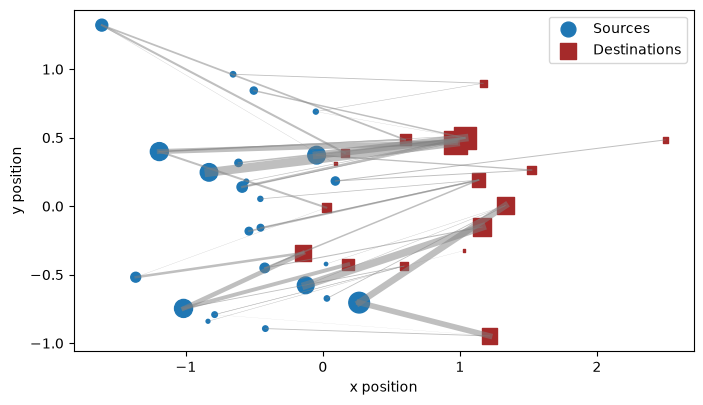

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))

for i, j in np.argwhere(plan > 1e-9):
    start, end = sources[i], destinations[j]
    ax.plot([start[0], end[0]], [start[1], end[1]],
            color="gray", alpha=0.5, linewidth=60 * plan[i, j])

ax.scatter(sources[:, 0], sources[:, 1], s=1500 * a, color="tab:blue", label="Sources")
ax.scatter(destinations[:, 0], destinations[:, 1], s=1500 * b, color="brown", marker="s", label="Destinations")
ax.set(xlabel="x position", ylabel="y position")
ax.set_aspect("equal")
ax.legend()
plt.show()

## Larger example

Same setup, now with 200 points on each side. How many routes are used?

In [6]:
n = 200
sources, destinations = point_clouds(n, n, seed=1720)
rng = np.random.default_rng(1720)
a = rng.dirichlet(np.ones(n))
b = rng.dirichlet(np.ones(n))
cost = cdist(sources, destinations, metric="sqeuclidean")
plan = solve_transport(a, b, cost)

print("Routes used:", np.count_nonzero(plan > 1e-9))
print("Bound for a corner solution:", len(a) + len(b) - 1)

Routes used: 399
Bound for a corner solution: 399


## Equal weights

Here each point gets 1/8 of the mass. Does the LP give the same cost as matching the points one to one?

In [7]:
sources, destinations = point_clouds(8, 8, seed=1702)
mass = np.full(8, 1 / 8)
cost = cdist(sources, destinations, metric="sqeuclidean")
plan = solve_transport(mass, mass, cost)

rows, columns = linear_sum_assignment(cost)
assignment_cost = cost[rows, columns].sum() / 8
print(f"Transport cost: {np.sum(plan * cost):.6g}")
print(f"Assignment cost: {assignment_cost:.6g}")
8 * plan

Transport cost: 3.22303
Assignment cost: 3.22303


array([[ 0.,  1.,  0.,  0.,  0.,  0.,  0.,  0.],
       [ 0.,  0.,  0., -0.,  0.,  0.,  1., -0.],
       [ 1., -0.,  0.,  0.,  0.,  0., -0.,  0.],
       [ 0.,  0.,  0.,  0.,  0.,  0.,  0.,  1.],
       [ 0.,  0., -0.,  0.,  0.,  1.,  0.,  0.],
       [ 0.,  0.,  0.,  1.,  0.,  0.,  0.,  0.],
       [ 0., -0.,  0.,  0.,  1.,  0.,  0.,  0.],
       [-0.,  0.,  1.,  0.,  0.,  0.,  0.,  0.]])

## What if all the costs are zero?

Compare the solver's plan with an even split. Both meet the same totals and cost zero. The even split uses four routes, above the corner bound of three.

In [8]:
mass = [0.5, 0.5]
cost = np.zeros((2, 2))
plan = solve_transport(mass, mass, cost)
split = np.full((2, 2), 0.25)

for label, table in [("Solver", plan), ("Even split", split)]:
    print(label)
    print(table)
    print("Routes used:", np.count_nonzero(table > 1e-9))
    print("Cost:", np.sum(table * cost))
    print()

Solver
[[-0.   0.5]
 [ 0.5  0. ]]
Routes used: 2
Cost: 0.0

Even split
[[0.25 0.25]
 [0.25 0.25]]
Routes used: 4
Cost: 0.0

